kernel: mlenv

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
from pyproj import Transformer
from scipy.ndimage import zoom
from functions_for_goes import crop_goes_to_latlon_box, convert_radiance_to_brightness_temp

In [2]:
region = 'SEP'  # 'SEP' or 'NEP'

if region == 'SEP':
    # SEP region (Southeast Pacific)
    lat_bounds = (-25, -2.5)
    lon_bounds = (-95, -75)
    times = ['1400', '1600', '1800', '2000', '2200', '0000']

elif region == 'NEP':
    # NEP region (Northeast Pacific)
    lat_bounds = (15, 35)
    lon_bounds = (-135, -115)
    times = ['1600', '1800', '2000', '2200', '0000']

# Functions to run judge on GOES data

In [3]:
# DEPRECATED: for the computation of judge for single windows
#from scipy.ndimage import zoom
#import numpy as np

# lat_j, lon_j = (-10, -85)
#def get_window_around_point(dataarray, lat_j, lon_j, window_size=100):
#    import numpy as np
#    # Get the latitude and longitude 2D coordinate arrays
#    lat_2d = dataarray.latitude
#    lon_2d = dataarray.longitude
#
#    # Calculate the distance from each grid point to the target point
#    # Using Euclidean distance (for small regions, this is sufficient)
#    distance = np.sqrt((lat_2d - lat_j)**2 + (lon_2d - lon_j)**2)
#
#    # Find the indices of the minimum distance
#    y_idx, x_idx = np.unravel_index(distance.argmin(), distance.shape)
#
#    # Extract the window around the target point
#    return dataarray[y_idx - window_size // 2 : y_idx + window_size // 2,
#                     x_idx - window_size // 2 : x_idx + window_size // 2]
#
#BT11_window = get_window_around_point(ds_11_cropped['BT'], lat_j, lon_j, window_size=128)
#BT14_window = get_window_around_point(ds_14_cropped['BT'], lat_j, lon_j, window_size=128)
#BT15_window = get_window_around_point(ds_15_cropped['BT'], lat_j, lon_j, window_size=128)
#COD_window = get_window_around_point(ds_COD_cropped['COD'], lat_j, lon_j, window_size=128//2)

# Simple interpolation without complex coordinate handling
#scale_factor = 128 / 64  # 2x upsampling
#COD_interpolated = zoom(COD_window.values, scale_factor, order=1)
#
## Create new xarray DataArray
#COD_window_128 = xr.DataArray(
#    COD_interpolated,
#    dims=['y', 'x']
#)
#
#print(f"Original shape: {COD_window.shape}")
#print(f"Interpolated shape: {COD_window_128.shape}")

In [4]:
def preprocess_data_for_single_window(BT11_window, BT14_window, BT15_window, COD_window_128, window_size=128, debugging=False):
    all_weirgb = []
    for i in range(2):
        # Convert to numpy arrays
        data11 = BT11_window.values
        data22 = BT14_window.values
        data33 = BT15_window.values

        gama_R = 1
        gama_G = 2
        gama_B = 1
        R = data33-data22 #Red
        G = data22-data11 #Green
        B = data22 #Blue

        #归一化 y = (x - xmin) / (xmax - xmin)
        L_bond = np.min(R)
        H_bond = np.max(R)
        R = np.clip(R, L_bond, H_bond)
        R = (R - L_bond) / (H_bond - L_bond)
        R = np.power(R, 1 / gama_R)
        
        L_bond = np.min(G)
        H_bond = np.max(G)
        G = np.clip(G, L_bond, H_bond)
        G = (G - L_bond) / (H_bond - L_bond)
        G = np.power(G, 1 / gama_G)

        L_bond = np.min(B)
        H_bond = np.max(B)
        B = np.clip(B, L_bond, H_bond)
        B = (B - L_bond) / (H_bond - L_bond)
        B = np.power(B, 1 / gama_B)

        #归一化cot  y = (x - xmin) / (xmax - xmin)
        cot1 = COD_window_128.values
        L_bond = np.min(cot1)
        H_bond = np.max(cot1)
        # 检查是否存在除以零的情况
        if L_bond == H_bond:
            cot2 = cot1.copy()  
        else:
            cot2 = (cot1 - L_bond) / (H_bond - L_bond)
        
        weirgb = np.zeros((4, 128, 128))

        weirgb[0, :, :] = R  #Red
        weirgb[1, :, :] = G  #Green
        weirgb[2, :, :] = B  #Blue
        weirgb[3, :, :] = cot2

        if debugging:
            import matplotlib.pyplot as plt
            plt.figure(figsize=(8, 3))
            plt.subplot(1, 2, 1)
            # Explicitly slice the RGB channels and document the expected shape
            rgb_image = weirgb[0:3, :, :]  # Shape should be (3, 128, 128)
            plt.imshow(rgb_image.transpose(1, 2, 0))  # Transpose to (128, 128, 3) for imshow
            plt.title('RGB Image')
            plt.subplot(1, 2, 2)
            plt.imshow(weirgb[3], cmap='gray')
            plt.title('COT Channel')
            plt.show()

        ice_pixel = (BT14_window.values < 273)
        ice_flag = np.sum(ice_pixel) / (window_size * window_size)
        all_weirgb.append(weirgb)

    all_weirgb = np.array(all_weirgb)

    return all_weirgb, ice_flag

#weirgb, ice_flag = preprocess_data_for_single_window(BT11_window, BT14_window, BT15_window, COD_window_128)

def preprocess_data(BT_11, BT_14, BT_15, COD, window_size=128, debugging=False):
    # Simple interpolation without complex coordinate handling
    scale_factor = 2 # 2x upscaling for COD2KMF; 4x upsampling is needed if CODF is used
    COD_interpolated = zoom(COD.values, scale_factor, order=1)
    # Create new xarray DataArray
    COD_interpolated = xr.DataArray(
        COD_interpolated,
        dims=['y', 'x']
    )

    scale_factor = 2
    latitudes = zoom(BT_11.latitude.values, scale_factor, order=1)
    longitudes = zoom(BT_11.longitude.values, scale_factor, order=1)
    BT_11 = zoom(BT_11.values, scale_factor, order=1)
    BT_14 = zoom(BT_14.values, scale_factor, order=1)
    BT_15 = zoom(BT_15.values, scale_factor, order=1)
    BT_11 = xr.DataArray(BT_11, dims=['y', 'x'])
    BT_14 = xr.DataArray(BT_14, dims=['y', 'x'])
    BT_15 = xr.DataArray(BT_15, dims=['y', 'x'])

    # make a grid of indices, s.t. they are always 128 pixels apart
    y_indices = np.arange(64, BT_11.shape[0] -64, 64) # 128)
    x_indices = np.arange(64, BT_11.shape[1] -64, 64) # 128

    num_scenes = y_indices.shape[0] * x_indices.shape[0]
    all_weirgb = []
    all_scenes_params = {'y_idx': [], 'x_idx': [], 'lon_mid': [], 'lat_mid': [], 'ice_flag': []}
    
    for j in y_indices:
        for i in x_indices:
            lat_mid = latitudes[j, i]
            lon_mid = longitudes[j, i]

            # get window data
            data11 = BT_11[j - window_size // 2 : j + window_size // 2,
                            i - window_size // 2 : i + window_size // 2].values
            data22 = BT_14[j - window_size // 2 : j + window_size // 2,
                            i - window_size // 2 : i + window_size // 2].values
            data33 = BT_15[j - window_size // 2 : j + window_size // 2,
                            i - window_size // 2 : i + window_size // 2].values

            gama_R = 1
            gama_G = 2
            gama_B = 1
            R = data33-data22 #Red
            G = data22-data11 #Green
            B = data22 #Blue

            #归一化 y = (x - xmin) / (xmax - xmin)
            L_bond = np.min(R)
            H_bond = np.max(R)
            R = np.clip(R, L_bond, H_bond)
            R = (R - L_bond) / (H_bond - L_bond)
            R = np.power(R, 1 / gama_R)
            
            L_bond = np.min(G)
            H_bond = np.max(G)
            G = np.clip(G, L_bond, H_bond)
            G = (G - L_bond) / (H_bond - L_bond)
            G = np.power(G, 1 / gama_G)

            L_bond = np.min(B)
            H_bond = np.max(B)
            B = np.clip(B, L_bond, H_bond)
            B = (B - L_bond) / (H_bond - L_bond)
            B = np.power(B, 1 / gama_B)

            #归一化cot  y = (x - xmin) / (xmax - xmin)
            cot1 = COD_interpolated[j - window_size // 2 : j + window_size // 2,
                                    i - window_size // 2 : i + window_size // 2].values
            L_bond = np.min(cot1)
            H_bond = np.max(cot1)
            # 检查是否存在除以零的情况
            if L_bond == H_bond:
                cot2 = cot1.copy()  
            else:
                cot2 = (cot1 - L_bond) / (H_bond - L_bond)
            
            weirgb = np.zeros((4, 128, 128))

            weirgb[0, :, :] = R  #Red
            weirgb[1, :, :] = G  #Green
            weirgb[2, :, :] = B  #Blue
            weirgb[3, :, :] = cot2

            if debugging:
                import matplotlib.pyplot as plt
                plt.figure(figsize=(8, 3))
                plt.subplot(1, 2, 1)
                # Explicitly slice the RGB channels and document the expected shape
                rgb_image = weirgb[0:3, :, :]  # Shape should be (3, 128, 128)
                plt.imshow(rgb_image.transpose(1, 2, 0))  # Transpose to (128, 128, 3) for imshow
                plt.title('RGB Image')
                plt.subplot(1, 2, 2)
                plt.imshow(weirgb[3], cmap='gray')
                plt.title('COT Channel')
                plt.show()

            ice_pixel = (data22 < 273)
            ice_flag = np.sum(ice_pixel) / (window_size * window_size)
            all_scenes_params['y_idx'].append(j)
            all_scenes_params['x_idx'].append(i)
            all_scenes_params['lon_mid'].append(lon_mid)
            all_scenes_params['lat_mid'].append(lat_mid)
            all_scenes_params['ice_flag'].append(ice_flag)

            all_weirgb.append(weirgb)

    all_weirgb = np.array(all_weirgb)

    return all_weirgb, all_scenes_params

In [5]:
import torch
from torch.utils.data import Dataset
import numpy as np
import scipy.stats
import xarray as xr
from typing import Tuple

class JudgeDataset(Dataset):
    def __init__(self, BT11, BT14, BT15, COD, debugging=False):
        self.data = []
        mat_data, all_scenes_params = preprocess_data(BT11, BT14, BT15, COD, window_size=128, debugging=False)
        print(mat_data.shape)
        if mat_data is not None:
            data = torch.from_numpy(mat_data)
            self.data.extend((data))
            self.scenes_params = all_scenes_params
        else:
            print("no data found!")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        data = self.data[idx]
        return data

In [6]:
import timm
from torch import nn
import torch
from torch.utils.data import DataLoader
import os
import numpy as np

# Only need input:
params = {
    'folder_path': './../Data_preprocess/',  # The path of the folder containing subfolders of .h5 files
    'model_path': '/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/finetuned_goes_model.pth',#'/home/jmayer/ACI_research/Code/mesoscale_structure/judge_original/64epochs_accuracy0.91456.pth',
    'batch_size': 512,
    'device_num': '1',
    'save_path':'./'
}


def save_batch_to_npz(all_cats, all_certs, subdirectory):
    npz_filename = f'judged_night_{subdirectory}.npz'
    npz_path = os.path.join(params['save_path'],subdirectory, npz_filename)
    if not os.path.exists(os.path.dirname(npz_path)):
        os.makedirs(os.path.dirname(npz_path))
    np.savez(npz_path, cats=all_cats, certs=all_certs)


def judge(judge_loader, model, class_names, device, save_to=None):
    model.eval()
    all_cats = []
    all_certs = []

    with torch.no_grad():
        for i, input in enumerate(judge_loader, start=1):
            # Debug shapes
            print(f"Input type: {type(input)}")
            print(f"Input shape: {input.shape if hasattr(input, 'shape') else 'No shape attr'}")
            
            # Handle the tensor properly
            if isinstance(input, (list, tuple)):
                input = input[0]  # Extract the tensor from list/tuple
            
            input = input.to(torch.float32).to(device)
            
            # Ensure 4D: (batch, channels, height, width)
            if input.dim() == 3:
                input = input.unsqueeze(0)  # Add batch dimension
                
            print(f"Final input shape: {input.shape}")
            output = model(input)
            y_pred = torch.softmax(output, dim=1).cpu()
            cert = torch.max(y_pred, dim=1).values.cpu() / torch.sum(y_pred, dim=1).cpu() 
            cat = torch.argmax(y_pred, dim=1).cpu().numpy()  
            print(cat,cert)
            all_cats.extend(cat)
            all_certs.extend(cert)
    
    all_cats = np.array(all_cats)
    all_certs = np.array(all_certs)
    print(all_cats.shape)
    #save_batch_to_npz(all_cats, all_certs, subdirectory)
    return all_cats, all_certs


def judge_MSI(BT11, BT14, BT15, COD, debugging=False):
    class_names = ['Solid stratus','Closed MCC', 'Open MCC','Disorganized MCC','Clustered Cu', 'Suppressed Cu'] #[0,1,2,3,4,5]
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
    device = torch.device('cuda:' + params['device_num'] if torch.cuda.is_available() else 'cpu')

    test_dataset = JudgeDataset(BT11, BT14, BT15, COD, debugging=debugging)
    test_len = JudgeDataset.__len__(test_dataset)
    scenes_params = test_dataset.scenes_params
    #test_dataloader = DataLoader(test_dataset, batch_size=params['batch_size'], shuffle=False)
    test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=False)  
    model = timm.create_model('resnet50d', pretrained=False)
    model.conv1 = nn.Conv2d(4, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.fc = nn.Linear(2048, 6)
    model = model.to(device)
    weights = torch.load(params['model_path'], map_location=device)
    model.load_state_dict(weights)
    model = model.to(device)
    
    cats, cert = judge(test_dataloader, model, class_names, device)

    del test_dataset
    del test_dataloader
    return cats, cert, scenes_params

/home/jmayer/miniconda3/envs/mlenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Run judge on GOES data

In [ ]:
save_path = '/home/jmayer/ACI_research/Code/resources/'
partial_results_filename = os.path.join(save_path, f'judge_results_GOES_{region}_partial.csv')
results_filename = os.path.join(save_path, f'judge_results_GOES_{region}.csv')
plot_path = f'/home/jmayer/ACI_research/Code/mesoscale_structure/figures_judge_goes_{region}/'

In [ ]:
save_path = '/home/jmayer/ACI_research/Code/resources/'
partial_results_filename = os.path.join(save_path, f'judge_results_GOES_{region}_partial1.csv')
results_filename = os.path.join(save_path, f'judge_results_GOES_{region}1.csv')
plot_path = f'/home/jmayer/ACI_research/Code/mesoscale_structure/figures_judge_goes_{region}/'

Checking date 20250801 time 1400...
Checking date 20250801 time 1600...
Checking date 20250801 time 1800...
Checking date 20250801 time 2000...
Checking date 20250801 time 2200...
Checking date 20250801 time 0000...
Checking date 20250802 time 1400...
Checking date 20250802 time 1600...
Checking date 20250802 time 1800...
Checking date 20250802 time 2000...
Checking date 20250802 time 2200...
Checking date 20250802 time 0000...
Checking date 20250803 time 1400...
Checking date 20250803 time 1600...
Checking date 20250803 time 1800...
Checking date 20250803 time 2000...
Checking date 20250803 time 2200...
Checking date 20250803 time 0000...
Checking date 20250804 time 1400...
Checking date 20250804 time 1600...
Checking date 20250804 time 1800...
Checking date 20250804 time 2000...
Checking date 20250804 time 2200...
Checking date 20250804 time 0000...
Checking date 20250805 time 1400...
Checking date 20250805 time 1600...
Checking date 20250805 time 1800...
Checking date 20250805 time 

/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1197, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Lat range: -25.56 to -2.29
Lon range: -97.96 to -74.81


/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1197, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Lat range: -25.56 to -2.29
Lon range: -97.96 to -74.81


/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


... (3 outputs left out)

/tmp/ipykernel_1339136/3121526233.py:77: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  weights = torch.load(params['model_path'], map_location=device)


Input type: <class 'torch.Tensor'>
Input shape: torch.Size([1, 4, 128, 128])
Final input shape: torch.Size([1, 4, 128, 128])
[4] tensor([0.7712])
Input type: <class 'torch.Tensor'>
Input shape: torch.Size([1, 4, 128, 128])
Final input shape: torch.Size([1, 4, 128, 128])
[4] tensor([0.9820])
Input type: <class 'torch.Tensor'>
Input shape: torch.Size([1, 4, 128, 128])
Final input shape: torch.Size([1, 4, 128, 128])
[4] tensor([0.4905])
Input type: <class 'torch.Tensor'>
Input shape: torch.Size([1, 4, 128, 128])
Final input shape: torch.Size([1, 4, 128, 128])
[2] tensor([0.4899])
Input type: <class 'torch.Tensor'>
Input shape: torch.Size([1, 4, 128, 128])
Final input shape: torch.Size([1, 4, 128, 128])
[4] tensor([0.7239])
Input type: <class 'torch.Tensor'>
Input shape: torch.Size([1, 4, 128, 128])
Final input shape: torch.Size([1, 4, 128, 128])
[4] tensor([0.6757])
Input type: <class 'torch.Tensor'>
Input shape: torch.Size([1, 4, 128, 128])
Final input shape: torch.Size([1, 4, 128, 128])

/tmp/ipykernel_1339136/137611031.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_results = pd.concat([df_results, df], ignore_index=True)


FileNotFoundError: [Errno 2] No such file or directory: '/home/jmayer/ACI_research/Code/causal_aci/figures_judge_goes_SEP/judge_202508191800_new.png'

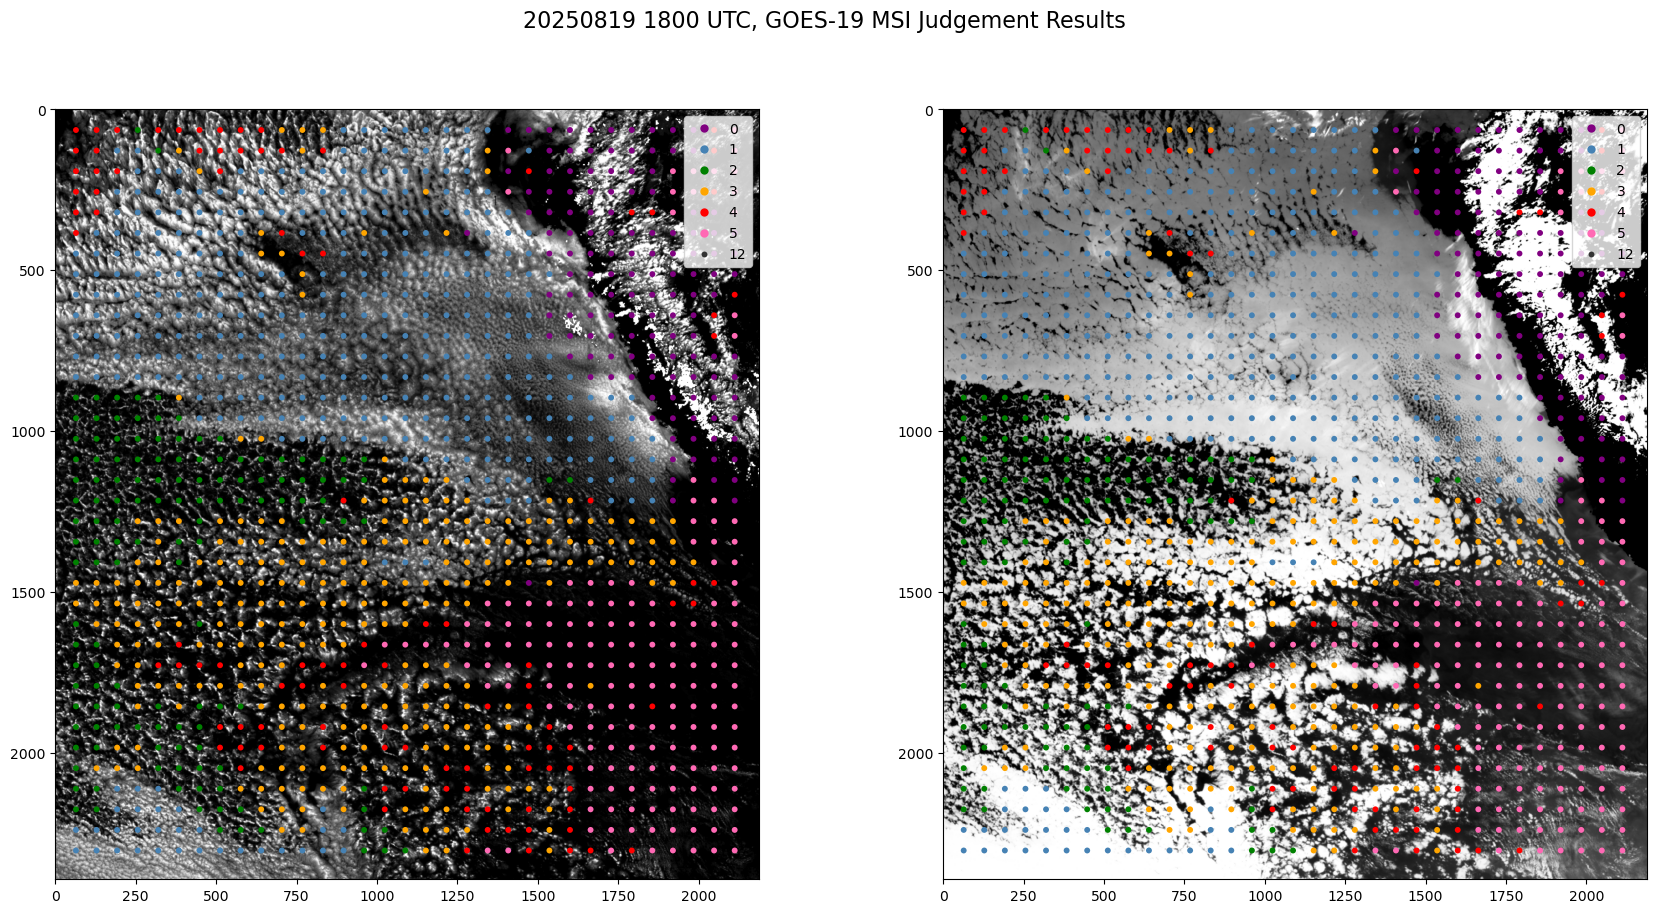

In [12]:
if os.path.exists(partial_results_filename):
    df_results = pd.read_csv(partial_results_filename)
    df_results['datetime'] = pd.to_datetime(df_results['datetime'])
else:
    df_results = pd.DataFrame(columns=['datetime', 'y_idx', 'x_idx', 'lon_mid', 'lat_mid', 'ice_flag', 'cats', 'cert'])

for day in ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31']:
    date = f'202508{day}'
    for time in times:
        print(f'Checking date {date} time {time}...')
        if day != '19' or time != '1800':
            continue

        ts = pd.to_datetime(date + time)
        if ts in df_results['datetime'].values:
            print(f'{date}{time} already contained in judge results for GOES. Skipping this datetime.../n')
            continue
        
        print('.'*85)
        print(f"Processing date {date} time {time}...")
        # Load and crop your GOES data
        with xr.open_dataset(f'/home/jmayer/Object_Data/GOES19/goes19_C11_RadF_{date}_{time}.nc') as ds:
            # Convert to brightness temperature
            ds = convert_radiance_to_brightness_temp(ds)
            # Crop to your region
            ds_11_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

        with xr.open_dataset(f'/home/jmayer/Object_Data/GOES19/goes19_C14_RadF_{date}_{time}.nc') as ds:
            # Convert to brightness temperature
            ds = convert_radiance_to_brightness_temp(ds)
            # Crop to your region
            ds_14_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

        with xr.open_dataset(f'/home/jmayer/Object_Data/GOES19/goes19_C15_RadF_{date}_{time}.nc') as ds:
            # Convert to brightness temperature
            ds = convert_radiance_to_brightness_temp(ds)
            # Crop to your region
            ds_15_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

        with xr.open_dataset(f'/home/jmayer/Object_Data/GOES19/goes19_COD2KMF_{date}_{time}.nc') as ds:
            # Crop to your region
            ds_COD_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

        print('.'*85)
        print('running JUDGE...')
        cats, cert, scenes_params = judge_MSI(ds_11_cropped['BT'], ds_14_cropped['BT'], ds_15_cropped['BT'], ds_COD_cropped['COD'])

        # save results to dataframe
        df = pd.DataFrame(scenes_params)
        df['cats'] = cats
        df['cert'] = cert
        df['datetime'] = pd.to_datetime(date+time)
        df_results = pd.concat([df_results, df], ignore_index=True)
        #df_results.to_csv(partial_results_filename, index=False)

        # Optional: visualize some results
        import seaborn as sns
        import matplotlib.pyplot as plt
        palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}
        fig, axs = plt.subplots(1, 2, figsize=(21, 10))
        COD_interpolated = zoom(ds_COD_cropped['COD'].values, 2, order=1)
        axs[0].imshow(COD_interpolated, vmax=35, cmap='Greys_r')
        BT_14_interpolated = zoom(ds_14_cropped['BT'].values, 2, order=1)
        axs[1].imshow(BT_14_interpolated, vmax=290, vmin=280, cmap='Greys')
        for ax in axs:
            sns.scatterplot(ax=ax, x=scenes_params['x_idx'], y=scenes_params['y_idx'], hue=cats, size=12, lw=0, palette=palette_goes_cats)
        plt.suptitle(f'{date} {time} UTC, GOES-19 MSI Judgement Results', fontsize=16)
        plt.savefig(os.path.join(plot_path, f'judge_{date}{time}_new.png'))
        break
    #break
#df_results.to_csv(results_filename, index=False)

In [ ]:
df_results = pd.read_csv(partial_results_filename)

In [10]:
df_results

,datetime,y_idx,x_idx,lon_mid,lat_mid,ice_flag,cats,cert
0,2025-08-01 18:00:00,64,64,-94.553077,-2.903803,0.000000,5,0.985067
1,2025-08-01 18:00:00,64,192,-93.293226,-2.900151,0.000000,0,0.465915
2,2025-08-01 18:00:00,64,320,-92.047694,-2.896772,0.000000,3,0.463463
3,2025-08-01 18:00:00,64,448,-90.815169,-2.893655,0.000000,3,0.984812
4,2025-08-01 18:00:00,64,576,-89.594434,-2.890793,0.000000,0,0.832485
...,...,...,...,...,...,...,...,...
45895,2025-08-30 22:00:00,2240,1600,-80.685626,-23.624969,7.970215,4,0.727357
45896,2025-08-30 22:00:00,2240,1728,-79.399576,-23.616774,7.970215,5,0.981107
45897,2025-08-30 22:00:00,2240,1856,-78.117166,-23.610680,7.970215,5,0.775433
45898,2025-08-30 22:00:00,2240,1984,-76.837316,-23.606670,7.970215,5,0.982034
